In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('IRIS.csv')

In [3]:
df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Признаков немного, это облегчает EDA

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


4 признака типа float и целевая переменная типа str

In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
df.shape

(150, 5)

Относительно небольшой датасет

In [7]:
import seaborn as sns

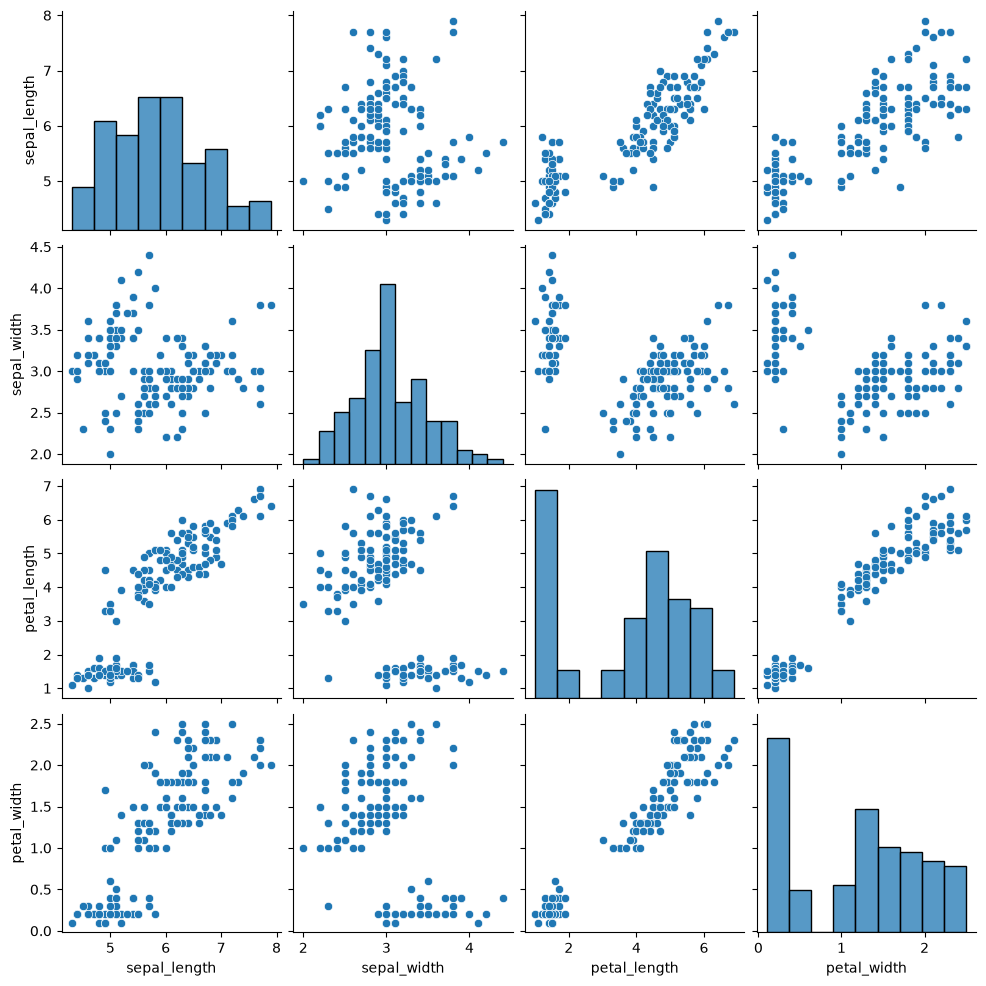

In [8]:
sns.pairplot(df)

Большая часть признаков имеет бимодальное распределение. Распределение sepal_width близко к нормальному. Прослеживаются корреляции, поэтому вероятно на этой задаче logistic regression сработает хорошо. 


<Axes: xlabel='petal_width', ylabel='Count'>

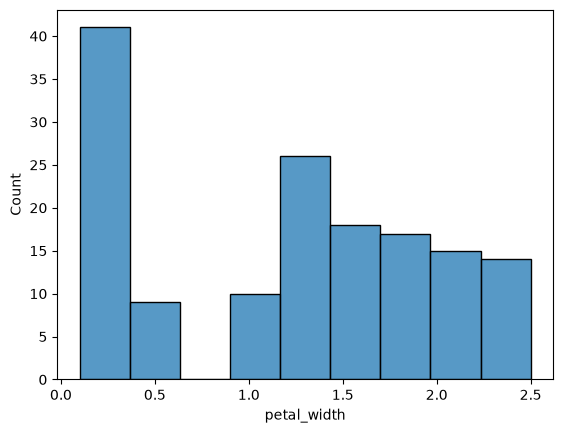

In [10]:
sns.histplot(df['petal_width'])

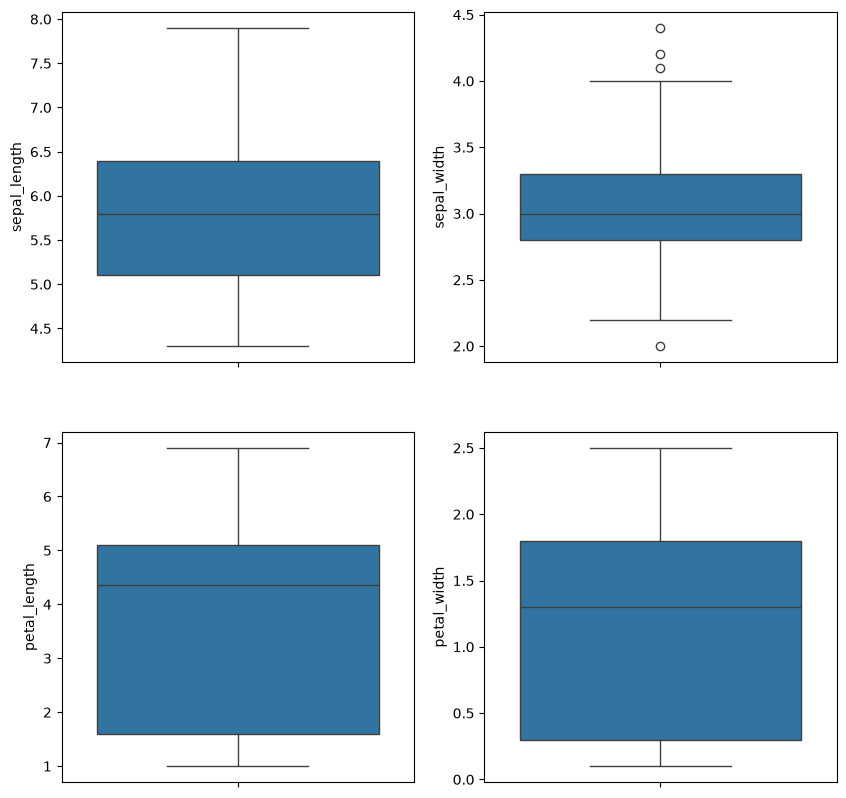

In [28]:
import matplotlib.pyplot as plt


n_cols = 2
n_rows = 2

fig, axes = plt.subplots(n_rows, n_cols, figsize = (10, n_rows * 5) )
axes = axes.flatten()

num_cols = df.select_dtypes(exclude=['str'])

for i, col in enumerate(num_cols):

    sns.boxplot(df[col], ax = axes[i])

plt.show()

Как можно заметить, выбросы есть только в признаке sepal_width, да и они в целом незначительные. Это опять же плюс для линейных моделей

In [61]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [48]:
X = num_cols
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.25, random_state=42)


In [49]:
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

log_reg_pred = log_reg.predict(X_test)

In [50]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

accuracy = accuracy_score(y_test, log_reg_pred)

In [51]:
accuracy

1.0

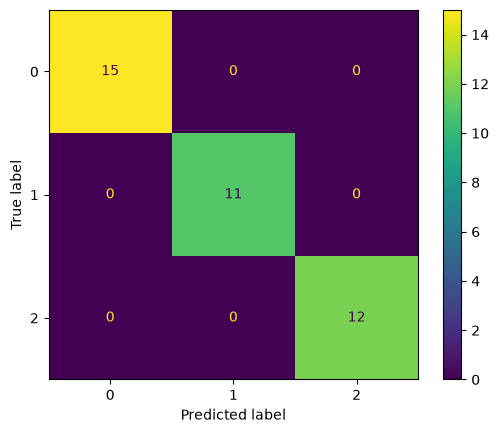

In [52]:
cm = confusion_matrix(y_test, log_reg_pred)
ConfusionMatrixDisplay(cm).plot()


Получаем идеальные предсказания. В целом неудивительно. Данных мало, корреляции сильные, выбросов почти нет, скрытых зависимостей тоже

In [54]:
svc = SVC()
svc.fit(X_train, y_train)

svc_pred = svc.predict(X_test) 
accuracy = accuracy_score(y_test, svc_pred)
accuracy

1.0

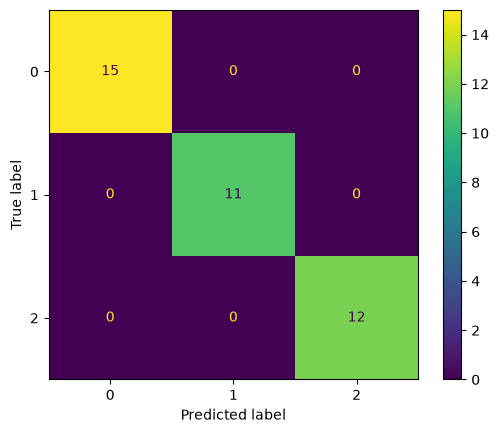

In [56]:
cm = confusion_matrix(y_test, svc_pred)
ConfusionMatrixDisplay(cm).plot()


Аналогично получаем идеальные предсказания.

In [58]:
dtc = DecisionTreeClassifier()
dtc.fit(X_train, y_train)

dtc_pred = dtc.predict(X_test)
accuracy = accuracy_score(y_test, dtc_pred)
accuracy

1.0

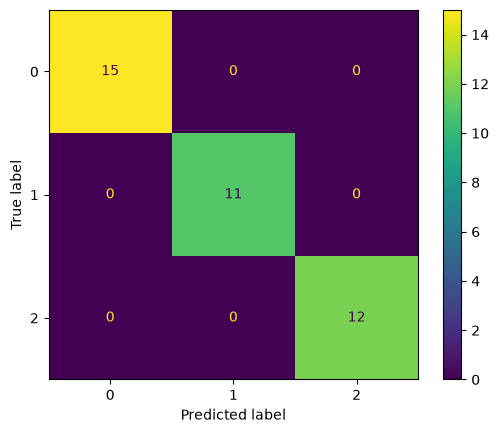

In [59]:
cm = confusion_matrix(y_test, dtc_pred)
ConfusionMatrixDisplay(cm).plot()

И тут идеальные предсказания

In [62]:
nb = GaussianNB()
nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)
accuracy = accuracy_score(y_test, nb_pred)

accuracy

1.0

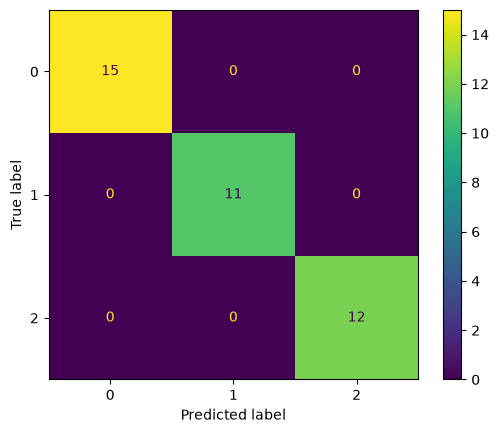

In [63]:
cm = confusion_matrix(y_test, nb_pred)
ConfusionMatrixDisplay(cm).plot()

И здесь тоже идеальные предсказания.

В целом датасет IRIS является учебным и очень хорошо структурированным, поэтому все модели дают идеальные предсказания. 